Crisp dm metodolojisi


In [17]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt

In [18]:
df=pd.read_csv('eksik_data.csv')
df.head()
df.isnull().sum()

ulke        0
boy         0
kilo        0
yas         2
cinsiyet    0
dtype: int64

In [ ]:
df['yas']
Q1=np.percentile(df['yas'],25)
Q3=np.percentile(df['yas'],75)
IQR=Q3-Q1
lower_fence=Q1-1.5*IQR
upper_fence=Q3+1.5*IQR
outlier = df[(df['yas'] < lower_fence) | (df['yas'] > upper_fence)]


,ulke,boy,kilo,yas,cinsiyet


In [26]:
df['yas'] = df['yas'].fillna(df['yas'].mean())
df['yas']

0     10.00
1     11.00
2     10.00
3      9.00
4     12.00
5     30.00
6     25.00
7     35.00
8     22.00
9     33.00
10    27.00
11    44.00
12    28.45
13    41.00
14    55.00
15    47.00
16    28.45
17    27.00
18    28.00
19    29.00
20    32.00
21    42.00
Name: yas, dtype: float64

## Polinom Regresyon

### 1. Nedir?
**Polinom regresyon**, bağımlı değişken $y$ ile bağımsız değişken $x$ arasındaki **doğrusal olmayan (eğrisel)** ilişkiyi modellemek için kullanılan bir regresyon yöntemidir.

Basit doğrusal regresyon veriye **düz bir çizgi** uydurur:

$$y = \beta_0 + \beta_1 x + \varepsilon$$

Ancak gerçek hayatta pek çok ilişki düz değildir (ör. yaş–maaş, sıcaklık–enerji tüketimi, zaman–büyüme). Polinom regresyon, $x$'in kuvvetlerini modele ekleyerek **eğri** uydurur:

$$y = \beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^3 + \dots + \beta_n x^n + \varepsilon$$

- $n$ → polinomun **derecesi (degree)**
- $\beta_0, \beta_1, \dots, \beta_n$ → modelin öğrendiği katsayılar
- $\varepsilon$ → hata terimi

### 2. Neden hâlâ "doğrusal" model sayılır?
Önemli bir nokta: polinom regresyon **katsayılara göre doğrusaldır**. $x^2, x^3, \dots$ terimlerini yeni özellikler (feature) gibi düşünürsek:

$$x_1 = x,\quad x_2 = x^2,\quad x_3 = x^3 \;\Rightarrow\; y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_3 x_3$$

Bu artık bir **çoklu doğrusal regresyondur**. Bu yüzden pratikte iki adım uygulanır:
1. `PolynomialFeatures` ile özellikleri dönüştür ($x \rightarrow [1, x, x^2, \dots, x^n]$)
2. Dönüştürülmüş veriye `LinearRegression` uygula (En Küçük Kareler yöntemi)

### 3. Derece Seçimi: Underfitting vs Overfitting
| Derece | Durum | Açıklama |
|---|---|---|
| Çok düşük (ör. 1) | **Underfitting** (yetersiz öğrenme) | Model veri yapısını yakalayamaz, yüksek bias |
| Uygun (ör. 2–4) | **İyi uyum** | Hem eğitim hem test verisinde başarılı |
| Çok yüksek (ör. 15) | **Overfitting** (aşırı öğrenme) | Gürültüyü ezberler, test verisinde kötü, yüksek varyans |

Doğru dereceyi seçmek için **train/test ayrımı** veya **cross-validation** ile test hatası (RMSE) / $R^2$ karşılaştırılır.

### 4. Avantajlar ve Dezavantajlar
**Avantajlar**
- Eğrisel ilişkileri basitçe modelleyebilir
- Yorumlanması ve uygulanması kolaydır
- Doğrusal regresyonun tüm araçları (OLS, metrikler) kullanılabilir

**Dezavantajlar**
- Yüksek derecelerde overfitting riski
- Aykırı değerlere (outlier) çok duyarlıdır → bu yüzden yukarıda IQR ile outlier analizi önemlidir
- Veri aralığının dışında (extrapolation) tahminler çok saçma olabilir
- Çok değişkenli durumda özellik sayısı hızla patlar

### 5. Dikkat Edilmesi Gerekenler
- Yüksek dereceli terimlerde ($x^{10}$ gibi) değerler çok büyüyebilir → **ölçekleme (`StandardScaler`)** faydalıdır
- Overfitting'i azaltmak için **Ridge / Lasso** gibi düzenlileştirme (regularization) yöntemleri ile birleştirilebilir
- `Pipeline` kullanmak, dönüşüm + model adımlarını tek nesnede toplar ve veri sızıntısını (data leakage) önler

### 6. Değerlendirme Metrikleri
- **MSE / RMSE**: Ortalama (karekök) kare hata — düşük olması iyi
- **MAE**: Ortalama mutlak hata
- **$R^2$**: Modelin açıkladığı varyans oranı (1'e yakın olması iyi)

Aşağıda sentetik bir veri ile adım adım örnek uygulama yer almaktadır.

In [2]:
# 1) Sentetik veri oluştur: eğrisel (kuadratik) ilişki + gürültü
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
np.random.seed(42)
X = np.sort(6 * np.random.rand(100, 1) - 3, axis=0)        # -3 ile 3 arası x
y = 0.5 * X[:, 0]**2 + X[:, 0] + 2 + np.random.randn(100)  # y = 0.5x² + x + 2 + gürültü

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# PolynomialFeatures ne yapıyor? x -> [1, x, x²]
poly = PolynomialFeatures(degree=2)
print("Orijinal x:", X[0])
print("Dönüştürülmüş [1, x, x²]:", poly.fit_transform(X[:1])[0])

Orijinal x: [-2.9668673]
Dönüştürülmüş [1, x, x²]: [ 1.         -2.9668673   8.80230156]


Derece  1 | Train RMSE: 1.630 | Test RMSE: 1.524 | Test R²: 0.381
Derece  2 | Train RMSE: 0.924 | Test RMSE: 0.833 | Test R²: 0.815
Derece 15 | Train RMSE: 0.873 | Test RMSE: 1.259 | Test R²: 0.578


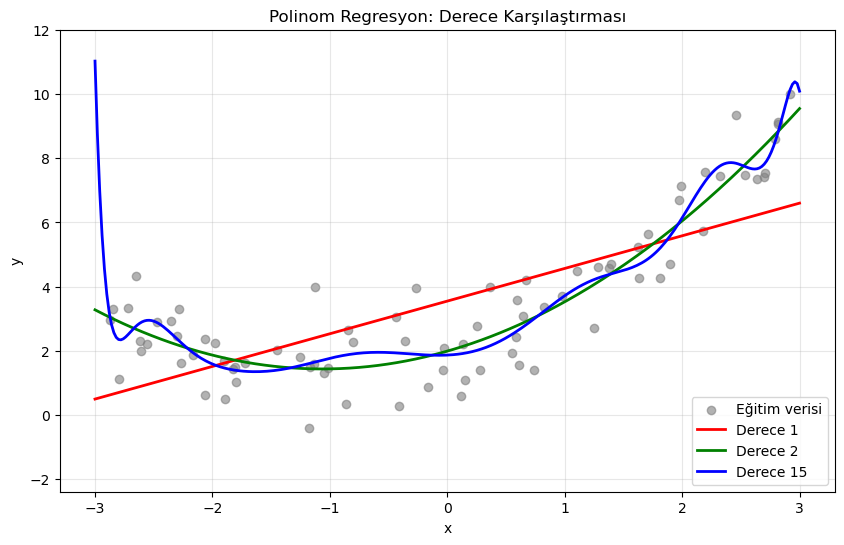


Öğrenilen model: y = 1.98 + 1.05x + 0.49x²


In [4]:
# 2) Farklı derecelerle model kur ve karşılaştır (underfitting / iyi uyum / overfitting)
import matplotlib.pyplot as plt
X_plot = np.linspace(-3, 3, 300).reshape(-1, 1)
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='gray', alpha=0.6, label='Eğitim verisi')

for degree, color in zip([1, 2, 15], ['red', 'green', 'blue']):
    model = make_pipeline(PolynomialFeatures(degree=degree), LinearRegression())
    model.fit(X_train, y_train)

    rmse_train = np.sqrt(mean_squared_error(y_train, model.predict(X_train)))
    rmse_test  = np.sqrt(mean_squared_error(y_test,  model.predict(X_test)))
    r2_test    = r2_score(y_test, model.predict(X_test))
    print(f"Derece {degree:>2} | Train RMSE: {rmse_train:.3f} | Test RMSE: {rmse_test:.3f} | Test R²: {r2_test:.3f}")

    plt.plot(X_plot, model.predict(X_plot), color=color, linewidth=2, label=f'Derece {degree}')

plt.ylim(y.min() - 2, y.max() + 2)
plt.xlabel('x'); plt.ylabel('y')
plt.title('Polinom Regresyon: Derece Karşılaştırması')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# Derece 2 modelinin katsayıları (gerçek değerler: β0=2, β1=1, β2=0.5)
best = make_pipeline(PolynomialFeatures(degree=2), LinearRegression()).fit(X_train, y_train)
lr = best.named_steps['linearregression']
print(f"\nÖğrenilen model: y = {lr.intercept_:.2f} + {lr.coef_[1]:.2f}x + {lr.coef_[2]:.2f}x²")

## Polinom Regresyonda Çoklu Doğrusal Bağlantı (Multicollinearity) ve Ridge Regresyon

---

### 1. Multicollinearity (Çoklu Doğrusal Bağlantı) Nedir?
Bağımsız değişkenlerin (özelliklerin) birbirleriyle **aşırı yüksek korelasyonlu** olması durumudur.
- Klasik regresyonda her bir katsayı ($\beta_j$), *"diğer tüm değişkenler sabit tutulduğunda o değişkenin $y$ üzerindeki tekil etkisi"* olarak yorumlanır.
- Eğer değişkenler birlikte hareket ediyorsa, model hangi etkinin hangi değişkene ait olduğunu matematiksel olarak ayıramaz.

---

### 2. Polinom Regresyonda Neden Kaçınılmazdır? (Yapısal Multicollinearity)
Polinom terimleri bağımsız farklı değişkenler değil, **aynı değişkenin kuvvetleridir**:
$$x, \; x^2, \; x^3, \; x^4, \; \dots, \; x^n$$
Özellikle $x$ pozitif değerlerden oluşuyorsa (ör. yaş, deneyim, fiyat, sıcaklık), $x$ arttıkça $x^2$, $x^3$ ve $x^4$ de kaçınılmaz olarak artar. Bu durum değişkenler arasında **0.95 – 0.999** düzeyinde devasa korelasyonlar yaratır. Buna literatürde **yapısal çoklu doğrusal bağlantı (structural multicollinearity)** denir.

---

### 3. Multicollinearity Polinom Fonksiyonda Ne Yapar? (Zararları)

| Etki | Açıklama |
|---|---|
| **Katsayı Patlaması (Coefficients Explosion)** | Model eğriyi uydurmaya çalışırken zıt işaretli devasa katsayılar üretir (ör. $\beta_2 = +5400$, $\beta_3 = -5900$). Artı ve eksi birbirini nötrlemeye çalışır. |
| **Aşırı Varyans ve Overfitting** | Verideki minicik bir gürültü veya tek bir veri noktasının değişmesi katsayıları altüst eder. Model eğitim verisindeki noktaları tutturmak için çılgınca zikzaklar çizer, test verisinde çuvallar. |
| **Matrisel Kararsızlık (Ill-Conditioned Matrix)** | Katsayılar analitik olarak $\beta = (X^T X)^{-1} X^T y$ formülüyle çözülür. Sütunlar neredeyse birbirinin katı olduğunda $X^T X$ matrisinin determinantı 0'a çok yaklaşır. Bilgisayar matrisin tersini alırken sayısal yuvarlama hataları ve kararsızlık tavan yapar. |
| **Yorumlanabilirlik Sıfırlanır** | Katsayıların standart hataları şişer, p-değerleri anlamsızlaşır; hangi terimin gerçekten etkili olduğunu söylemek imkansızlaşır. |

> ⚠️ **Özet:** Multicollinearity eğitim seti üzerinde $R^2$'yi düşürmez (hatta sahte bir yükseklik verir), ancak katsayıları çıldırtarak modelin **genelleme gücünü (test performansını)** yok eder.

---

### 4. Ridge Regresyon (L2 Regularization) Nedir ve Ne Yapar?

Ridge regresyon, klasik regresyonun hata fonksiyonuna katsayıların karelerinin toplamını bir **ceza (penalty)** terimi olarak ekler:

$$\text{Maliyet (Cost)} = \sum_{i=1}^m \left(y_i - \hat{y}_i\right)^2 + \alpha \sum_{j=1}^p \beta_j^2 = \text{MSE} + \alpha \|\beta\|_2^2$$

- **$\alpha$ (Alpha / Lambda):** Düzenlileştirme şiddetini belirleyen hiperparametredir.
  - $\alpha = 0$: Klasik Doğrusal Regresyon (OLS). Ceza yok, katsayılar patlamaya açık.
  - $\alpha \to \infty$: Bütün katsayılar sıfıra yaklaşır (aşırı basitleşme / underfitting).
  - Doğru $\alpha$: Çapraz doğrulama (**Cross-Validation**) ile belirlenir.

#### Ridge Ne Yapar? (Multicollinearity Panzehiri)
1. **Katsayı Büzülmesi (Shrinkage):** Ceza terimi sayesinde katsayıların devasa boyutlara (+5000, -5000 gibi) fırlamasını engeller, onları sıfıra doğru çeker ve dizginler. (Not: Katsayıları küçültür ama Lasso gibi tamamen sıfır yapmaz).
2. **Matrisel Düzeltme (Tersi Alınabilirlik):** Ridge'in matematiksel çözümü şöyledir:
   $$\beta_{\text{ridge}} = \left( X^T X + \alpha I \right)^{-1} X^T y$$
   Burada $I$ birim matristir. Köşegene eklenen pozitif $\alpha$ değeri sayesinde, daha önce tekil (singular) veya tersi alınması kararsız olan $X^T X$ matrisi **kesinlikle tersi alınabilir ve kararlı** hale gelir.
3. **Varyansı Düşürür (Bias-Variance Dengesi):** Modele çok ufak bir yanlılık (bias) katar, ancak varyansı (dalgalanmayı ve aşırı ezberlemeyi) dramatik şekilde düşürür. Böylece test hatası minimuma iner.

---

### 5. Kritik Kural: Standartlaştırma (StandardScaler) Neden Şarttır?
Ridge ceza teriminde $\sum \beta_j^2$ kullanır. Yani **katsayının mutlak büyüklüğüne** bakar:
- $x \in [1, 5]$ iken $x^5 \in [1, 3125]$ olur.
- Ölçeklendirme yapılmazsa, $x^5$ sütunundaki sayılar çok büyük olduğu için onun katsayısı doğal olarak çok küçük çıkar ve Ridge ona neredeyse hiç ceza kesmez; tam tersine küçük ölçekli $x$ sütununa haksız ceza keser!
- **Kural:** Polinom + Ridge uygulanırken **MUTLAKA** önce özellikler standartlaştırılmalıdır (`StandardScaler`).

---

### 6. Nasıl Yapılır? (İdeal İş Akışı)
1. Özellikleri türet: `PolynomialFeatures(degree=d)`
2. Özellikleri standartlaştır: `StandardScaler()`
3. Ridge modelini en iyi $\alpha$ ile kur: `RidgeCV(alphas=...)`
4. Hepsini veri sızıntısını (data leakage) önlemek için tek bir `Pipeline` içine al.

Aşağıdaki kod hücresinde multicollinearity kanıtı, OLS'in katsayı patlaması ve Ridge'in bunu nasıl pürüzsüzleştirdiği uygulamalı olarak gösterilmiştir.

1. POLİNOM DERECELERİ ARASINDAKİ KORELASYON (Multicollinearity Kanıtı):
       x^1    x^2    x^3    x^4
x^1  1.000  0.978  0.934  0.886
x^2  0.978  1.000  0.987  0.960
x^3  0.934  0.987  1.000  0.992
x^4  0.886  0.960  0.992  1.000
-> Görüldüğü gibi x ile x^2, x^3 arasında 0.90 - 0.99 korelasyon vardır!

2. KATSAYILARIN KARŞILAŞTIRILMASI (Derece = 7):
     OLS Katsayıları (Patlayan)  Ridge Katsayıları (Büzülmüş)
x^1                     -199.14                          2.47
x^2                     1629.17                          2.29
x^3                    -5888.89                          1.51
x^4                    11678.29                          0.74
x^5                   -13018.20                          0.18
x^6                     7640.12                         -0.14
x^7                    -1834.89                         -0.28

RidgeCV tarafından seçilen ideal alpha: 0.4942

3. TEST SETİ PERFORMANSLARI:
OLS (Doğrusal)  -> Test RMSE: 1.422 | Test R²: 0.948
Ridge (L2)      -> 

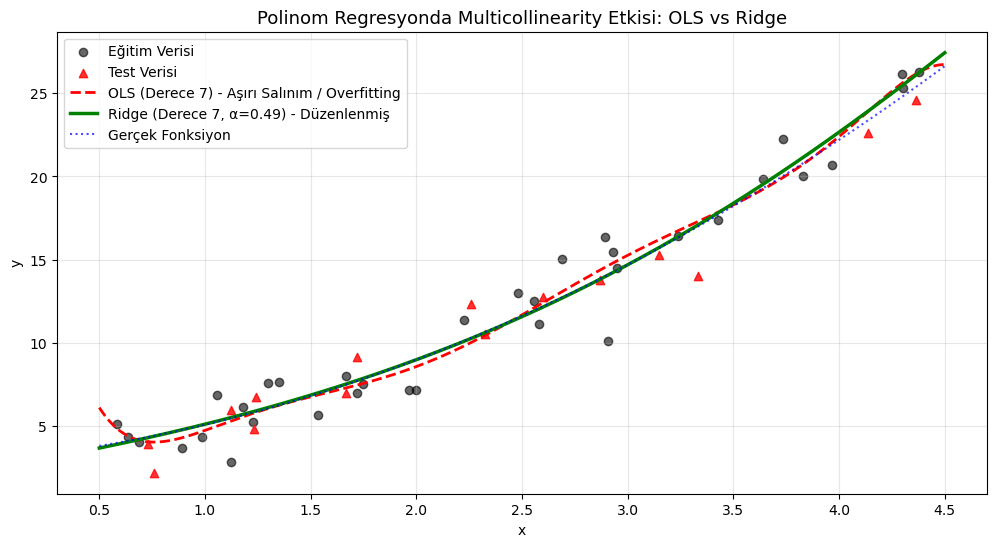

In [5]:
# ==============================================================================
# POLİNOM REGRESYONDA MULTICOLLINEARITY & RIDGE REGRESYON UYGULAMASI
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# 1) Veri Üretimi (Kuadratik ilişki + gürültü)
np.random.seed(42)
X = np.sort(np.random.uniform(0.5, 4.5, 50)).reshape(-1, 1)
y = 3.0 + 1.2 * X[:, 0] + 0.9 * X[:, 0]**2 + np.random.normal(0, 1.5, 50)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# ------------------------------------------------------------------------------
# ADIM 1: MULTICOLLINEARITY TESPİTİ (Korelasyon Matrisi)
# ------------------------------------------------------------------------------
poly_sample = PolynomialFeatures(degree=4, include_bias=False)
X_poly_sample = poly_sample.fit_transform(X)
corr_matrix = pd.DataFrame(X_poly_sample, columns=[f'x^{i}' for i in range(1, 5)]).corr()

print("="*60)
print("1. POLİNOM DERECELERİ ARASINDAKİ KORELASYON (Multicollinearity Kanıtı):")
print("="*60)
print(corr_matrix.round(3))
print("-> Görüldüğü gibi x ile x^2, x^3 arasında 0.90 - 0.99 korelasyon vardır!\n")

# ------------------------------------------------------------------------------
# ADIM 2: YÜKSEK DERECELİ MODELLEME (Derece = 7)
# OLS (Linear Regression) vs Ridge (L2 Regularization)
# ------------------------------------------------------------------------------
degree = 7

# Model A: Standart OLS Regresyon (StandardScaler ile birlikte)
pipe_ols = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('ols', LinearRegression())
])
pipe_ols.fit(X_train, y_train)

# Model B: StandardScaler + RidgeCV (En iyi alpha otomatik seçilir)
alphas = np.logspace(-3, 3, 50)
pipe_ridge = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', RidgeCV(alphas=alphas, cv=5))
])
pipe_ridge.fit(X_train, y_train)
best_alpha = pipe_ridge.named_steps['ridge'].alpha_

# ------------------------------------------------------------------------------
# ADIM 3: KATSAYILARIN KARŞILAŞTIRILMASI (Katsayı Patlaması vs Büzülme)
# ------------------------------------------------------------------------------
coef_df = pd.DataFrame({
    'OLS Katsayıları (Patlayan)': pipe_ols.named_steps['ols'].coef_,
    'Ridge Katsayıları (Büzülmüş)': pipe_ridge.named_steps['ridge'].coef_
}, index=[f'x^{i}' for i in range(1, degree + 1)])

print("="*60)
print(f"2. KATSAYILARIN KARŞILAŞTIRILMASI (Derece = {degree}):")
print("="*60)
print(coef_df.round(2))
print(f"\nRidgeCV tarafından seçilen ideal alpha: {best_alpha:.4f}\n")

# ------------------------------------------------------------------------------
# ADIM 4: TEST PERFORMANSI
# ------------------------------------------------------------------------------
rmse_ols = np.sqrt(mean_squared_error(y_test, pipe_ols.predict(X_test)))
r2_ols = r2_score(y_test, pipe_ols.predict(X_test))

rmse_ridge = np.sqrt(mean_squared_error(y_test, pipe_ridge.predict(X_test)))
r2_ridge = r2_score(y_test, pipe_ridge.predict(X_test))

print("="*60)
print("3. TEST SETİ PERFORMANSLARI:")
print("="*60)
print(f"OLS (Doğrusal)  -> Test RMSE: {rmse_ols:.3f} | Test R²: {r2_ols:.3f}")
print(f"Ridge (L2)      -> Test RMSE: {rmse_ridge:.3f} | Test R²: {r2_ridge:.3f}")

# ------------------------------------------------------------------------------
# ADIM 5: GÖRSELLEŞTİRME (Overfitting vs Ridge Pürüzsüzlüğü)
# ------------------------------------------------------------------------------
X_grid = np.linspace(0.5, 4.5, 300).reshape(-1, 1)

plt.figure(figsize=(12, 6))
plt.scatter(X_train, y_train, color='black', alpha=0.6, label='Eğitim Verisi')
plt.scatter(X_test, y_test, color='red', alpha=0.8, marker='^', label='Test Verisi')

plt.plot(X_grid, pipe_ols.predict(X_grid), 'r--', linewidth=2, label=f'OLS (Derece {degree}) - Aşırı Salınım / Overfitting')
plt.plot(X_grid, pipe_ridge.predict(X_grid), 'g-', linewidth=2.5, label=f'Ridge (Derece {degree}, α={best_alpha:.2f}) - Düzenlenmiş')

# Gerçek fonksiyon eğrisi
y_true = 3.0 + 1.2 * X_grid[:, 0] + 0.9 * X_grid[:, 0]**2
plt.plot(X_grid, y_true, 'b:', linewidth=1.5, alpha=0.7, label='Gerçek Fonksiyon')

plt.title('Polinom Regresyonda Multicollinearity Etkisi: OLS vs Ridge', fontsize=13)
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
#ridge hatayı minimize eder  lasso çoğu değeri 0 yapar
#lasso da max_iter kullanılır .genelde 100k olur

## GridSearchCV (Grid Search Cross-Validation)

---

### 1. Nedir ve Ne Yapar?
Modelin performansını en üst düzeye çıkaran **en iyi hiperparametre kombinasyonunu** bulmak için kullanılan kapsamlı bir arama yöntemidir. 
- Belirlediğimiz parametre aralıklarının (ör. polinom derecesi: 1, 2, 3 ve Ridge $\alpha$: 0.01, 1, 10) **tüm olası kombinasyonlarını (kartezyen çarpımını)** tek tek dener.
- Her kombinasyonu **K-Katlı Çapraz Doğrulama (K-Fold CV)** ile test eder.
- En yüksek skoru veren en iyi modeli otomatik olarak seçip tüm eğitim verisiyle yeniden eğitir.

---

### 2. Parametreler Ne İşe Yarar?

| Parametre | Ne İşe Yarar? / Açıklama |
|---|---|
| **`estimator`** | Hiperparametreleri optimize edilecek model veya `Pipeline` nesnesidir (ör. `Ridge()`, `Lasso()`, `Pipeline(...)`). |
| **`param_grid`** | Denenecek parametre isimlerini ve değer listelerini içeren bir sözlüktür (`dict`). *Pipeline kullanılıyorsa format: `{'adımAdı__parametreAdı': [liste]}` (ör. `'poly__degree': [1, 2, 3]`).* |
| **`cv`** | Çapraz doğrulama (Cross-Validation) kat sayısıdır (ör. `cv=5` $\rightarrow$ veriyi 5 eşit parçaya böler; her seferinde 4 parçayla eğitip 1 parçayla test eder). |
| **`scoring`** | En iyi modeli belirlerken optimize edilecek başarı metriğidir (ör. regresyon için `'neg_mean_squared_error'`, `'r2'`; sınıflandırma için `'accuracy'`, `'f1'`, `'roc_auc'`). *Not: Scikit-learn optimizasyonda maksimize etmeye çalıştığı için MSE skoru eksi (`neg_`) işaretle döner.* |
| **`n_jobs`** | Aramanın kaç işlemci çekirdeğinde paralel çalışacağını belirler. `n_jobs=-1` verilirse bilgisayarın tüm CPU çekirdekleri kullanılır ve arama ciddi şekilde hızlanır. |
| **`verbose`** | Arama sırasında ekrana basılacak bilgi/log detay seviyesidir (`0`: sessiz, `1`: kaç deneme yapıldığını söyler, `2`: süre ve fold detaylarını gösterir). |
| **`return_train_score`** | `True` yapılırsa sadece test skorunu değil, her denemedeki eğitim seti skorunu da kaydeder (aşırı öğrenme / overfitting kontrolü için faydalıdır). |

---

### 3. Önemli Çıktı Nitelikleri (Attributes)

| Nitelik | Anlamı |
|---|---|
| **`grid.best_params_`** | En yüksek skoru veren en iyi parametre kombinasyonu sözlüğü. |
| **`grid.best_score_`** | En iyi kombinasyonun çapraz doğrulama (CV) başarı ortalaması. |
| **`grid.best_estimator_`** | En iyi parametrelerle eğitilmiş, doğrudan `predict()` çağrılabilen hazır nihai model. |
| **`grid.cv_results_`** | Denediği tüm kombinasyonların skorlarını, sürelerini içeren detaylı tablo (`pd.DataFrame(grid.cv_results_)` ile incelenebilir). |

In [9]:
# ==============================================================================
# GridSearchCV KULLANIMI: Polinom Derecesi ve Ridge Alfa Optimizasyonu
# ==============================================================================
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

# 1. Pipeline Tanımlama (Adım adları: 'poly', 'scaler', 'ridge')
pipeline = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])

# 2. Denenecek Parametre Izgarası (param_grid)
# Not: Pipeline içindeki adımlara erişmek için 'adımAdı__parametreAdı' kullanılır
param_grid = {
    'poly__degree': [1, 2, 3, 5, 7],                      # Hangi polinom derecesi en iyi?
    'ridge__alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0] # Hangi ceza katsayısı en iyi?
}

# 3. GridSearchCV Modelini Başlatma
grid = GridSearchCV(
    estimator=pipeline,                   # Optimize edilecek model/pipeline
    param_grid=param_grid,                # Denenecek parametre sözlüğü
    cv=5,                                 # 5-Katlı Çapraz Doğrulama (K-Fold CV)
    scoring='neg_mean_squared_error',     # Regresyonda MSE minimizasyonu
    n_jobs=-1,                            # Tüm CPU çekirdeklerini kullan (hızlı)
    verbose=1                             # İlerleme durumunu göster
)

# 4. Aramayı Başlatma (Fitting)
grid.fit(X_train, y_train)

# 5. En İyi Sonuçları Yazdırma
print("="*55)
print("En İyi Parametreler :", grid.best_params_)
print(f"En İyi CV Skoru (MSE): {-grid.best_score_:.4f}")
print("="*55)

# 6. En İyi Model ile Test Seti Tahmini
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(f"Test Seti RMSE       : {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Test Seti R²         : {r2_score(y_test, y_pred):.4f}")


Fitting 5 folds for each of 30 candidates, totalling 150 fits
En İyi Parametreler : {'poly__degree': 2, 'ridge__alpha': 0.01}
En İyi CV Skoru (MSE): 2.1638
Test Seti RMSE       : 1.3819
Test Seti R²         : 0.9512


In [10]:
from sklearn.linear_model import Ridge
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

data = fetch_california_housing(as_frame=True)
X = data.data
y = data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Ridge(alpha=1.0) modelini kur
ridge_model = Ridge(alpha=1.0)

# 2. Modeli X_train, y_train ile eğit
ridge_model.fit(X_train, y_train)

# 3. Test R² hesapla ve yazdır (Ridge sınıfının .score metodu varsayılan olarak R² döndürür)
r2_score = ridge_model.score(X_test, y_test)
print(f"Test R² Skoru: {r2_score:.4f}")

Test R² Skoru: 0.5759
